In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 

torch.set_default_dtype(torch.float64)
MC_SAMPLES = 512
sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))

from botorch.test_functions.multi_objective import BraninCurrin
tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}
problem = BraninCurrin(negate=True).to(**tkwargs)

ININITIAL_SAMPLING_NUM = 2

np.random.seed(42)
torch.manual_seed(42)

/home/yibin/anaconda3/envs/botorch/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
data_total = []
for repeat in range(4,16):
    # initial random sampling
    train_observation_x = torch.cat([torch.rand(ININITIAL_SAMPLING_NUM, 2), 
                                     torch.randint(3, (ININITIAL_SAMPLING_NUM, 1))/2, 
                                     torch.randint(3, (ININITIAL_SAMPLING_NUM, 1))/2], dim=-1)
    train_observation_y = problem(train_observation_x[:,0:2])
    for budget in range(100):
        print(f"{repeat}_{budget} \r")
        # normalize training x to [0,1]
        train_x = train_observation_x
        # standarize train_y
        train_y = standardize(train_observation_y)
        # get models and train the models
        mll, model = botorch_tool.tools.initialize_model(train_x = train_x, train_obj = train_y, cat_dims = [2,3])
        fit_gpytorch_mll(mll)
        # define the boundaries for the optimization problem 
        bounds = torch.stack([torch.zeros(train_x.shape[1]), torch.ones(train_x.shape[1])])
        categorical_values = {2: [0, 0.5, 1.0], 3: [0, 0.5, 1.0]}
        key_set = list(categorical_values.keys())
        value_set = list(categorical_values.values())
        fixed_features_list = []
        for i in value_set[0]:
            for j in value_set[1]:
                fixed_features_list.append({key_set[0] : i, key_set[1] : j})
                
        # get the candidate 
        MC_SAMPLES = 512
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
        candidate = botorch_tool.tools.optimize_qehvi_and_get_observation(
            model = model, 
            train_x = train_x, 
            sampler = sampler, 
            ref_point = [0,0],
            cat_dims = [2,3], 
            fixed_features_list = fixed_features_list)
        train_observation_x = torch.concat((train_observation_x,candidate))
        train_observation_y = torch.concat((train_observation_y,problem(candidate)))
        
    data_total.append(
        [train_observation_x,train_observation_y]
    )

4_0 
4_1 
4_2 
4_3 
4_4 
4_5 


In [ ]:
import pickle
with open(f"./qehvi4_16.pkl", 'wb') as fp:
    pickle.dump(data_total, fp)

In [13]:
f = open('./qehvi.pkl', 'rb')
data2 = pickle.load(f)  

In [23]:
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)
from botorch.utils.multi_objective.pareto import is_non_dominated

hvs_list_total = []
for i in range(4):
    train_observation_y = data2[i][1]
    hvs_list = []
    for i in range(len(train_observation_y)-ININITIAL_SAMPLING_NUM):
        bd = DominatedPartitioning(ref_point=problem.ref_point, 
                                   Y = train_observation_y[0:ININITIAL_SAMPLING_NUM+i])
        volume = bd.compute_hypervolume().item()
        hvs_list.append(volume)
    hvs_list_total.append(hvs_list)

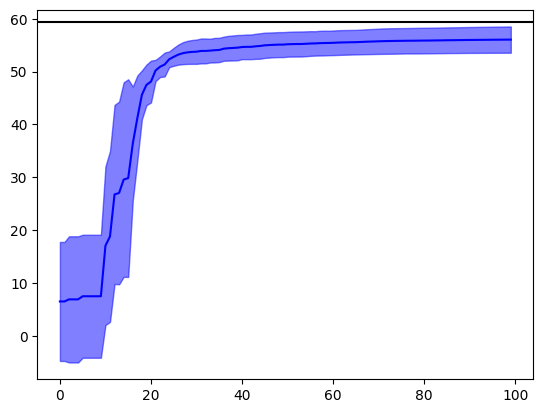

In [43]:
from matplotlib import pyplot as plt
hvs_list_total = np.array(hvs_list_total)

plt.plot(hvs_list_total.mean(axis = 0), color = "blue")
plt.fill_between(np.arange(len(hvs_list_total.mean(axis = 0))), 
                 hvs_list_total.mean(axis = 0) + hvs_list_total.std(axis = 0), 
                 hvs_list_total.mean(axis = 0) - hvs_list_total.std(axis = 0),
                 color='blue', alpha=0.5)

plt.axhline(problem.max_hv, color = "black")

In [33]:
problem.max_hv

59.36011874867746

In [44]:
hvs_list_total.mean(axis = 0)

array([ 6.50190264,  6.50190264,  6.89370535,  6.89370535,  6.89370535,
        7.48615428,  7.48615428,  7.48615428,  7.48615428,  7.48615428,
       17.04878116, 18.80591062, 26.7498638 , 27.03857068, 29.56337351,
       29.84466002, 36.35450798, 41.17381088, 45.59502697, 47.47802641,
       48.11558837, 50.20335993, 50.91845239, 51.33866816, 52.33447462,
       52.79765655, 53.21234646, 53.48220078, 53.63830301, 53.72158744,
       53.76545106, 53.90887412, 53.90887412, 53.9702132 , 54.05034701,
       54.09610765, 54.33492843, 54.42523289, 54.47093446, 54.52842326,
       54.64711641, 54.68310538, 54.68420912, 54.78743756, 54.84990818,
       54.97636996, 55.02090682, 55.06808367, 55.10415696, 55.10415696,
       55.1755019 , 55.19925391, 55.2161605 , 55.22074404, 55.26177186,
       55.31392987, 55.33087144, 55.38077067, 55.40237683, 55.41891826,
       55.44459167, 55.48959284, 55.51496276, 55.5340089 , 55.55512845,
       55.57163399, 55.60437931, 55.64397089, 55.67428766, 55.70